# Healthcare Analytics for Doctor Visits

## Purpose and scope
This notebook analyzes 5,190 person records to understand patterns in doctor visits. It documents the data audit, cleaning, exploratory analysis, statistical checks, and practical implications in plain language. Results describe associations in this dataset; they do not show causes. The supplied guide does not specify the survey period, sampling method, or units and direction for the coded age, income, and health fields.

# Import Library and Data

In [ ]:
# Import Library
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)


In [24]:
# Import Data 
raw = pd.read_csv(r"C:\VOIS Internship\Health Care Part 2\data\DoctorVisit.csv")
print(f"Loaded {raw.shape[1]} rows and {raw.shape[1]} columns")
print(raw.head())

Loaded 13 rows and 13 columns
   Unnamed: 0  visits  gender   age  income  illness  reduced  health private  \
0           1       1  female  0.19    0.55        1        4       1     yes   
1           2       1  female  0.19    0.45        1        2       1     yes   
2           3       1    male  0.19    0.90        3        0       0      no   
3           4       1    male  0.19    0.15        1        0       0      no   
4           5       1    male  0.19    0.45        2        5       1      no   

  freepoor freerepat nchronic lchronic  
0       no        no       no       no  
1       no        no       no       no  
2       no        no       no       no  
3       no        no       no       no  
4       no        no      yes       no  


## 1. Data audit
The audit checks size, data types, missingness, duplicates, record IDs, categories, and observed ranges. The record ID is only for traceability, not a health measure.

In [25]:
numeric = ["visits","age","income","illness","reduced","health"]
categories = ["gender","private","freepoor","freerepat","nchronic","lchronic"]

print("Shape:", raw.shape)
print(raw.dtypes.rename("data type").to_frame())
print(raw.isna().sum().rename("missing rows").to_frame())
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate IDs:", raw["Unnamed: 0"].duplicated().sum())
print("Unique IDs:", raw["Unnamed: 0"].nunique())
print(raw[numeric].describe().T)
for c in categories: print(c, raw[c].value_counts(dropna=False).to_dict())
print(pd.DataFrame({"minimum":raw[numeric].min(),"maximum":raw[numeric].max()}))

Shape: (5190, 13)
           data type
Unnamed: 0     int64
visits         int64
gender           str
age          float64
income       float64
illness        int64
reduced        int64
health         int64
private          str
freepoor         str
freerepat        str
nchronic         str
lchronic         str
            missing rows
Unnamed: 0             0
visits                 0
gender                 0
age                    0
income                 0
illness                0
reduced                0
health                 0
private                0
freepoor               0
freerepat              0
nchronic               0
lchronic               0
Exact duplicate rows: 0
Duplicate IDs: 0
Unique IDs: 5190
          count      mean       std   min   25%   50%   75%    max
visits   5190.0  0.301734  0.798134  0.00  0.00  0.00  0.00   9.00
age      5190.0  0.406385  0.204782  0.19  0.22  0.32  0.62   0.72
income   5190.0  0.583160  0.368907  0.00  0.25  0.55  0.90   1.50
illness  519

### Audit findings
All 5,190 records have values in all 13 columns. The record ID is unique and there are no duplicate rows. Count fields are nonnegative integers. Gender and yes/no fields use consistent labels. Age and income are fractional coded values whose units are not described. The health field's direction is also undefined in the supplied guide.

## 2. Cleaning and preprocessing
Cleaning is limited to renaming the unnamed ID column, trimming and normalizing text labels, converting numeric columns explicitly, and marking category fields as categories. No rows are removed or imputed because the audit finds no missing or invalid values. The ID is preserved but excluded from analysis.

In [26]:
df = raw.rename(columns={"Unnamed: 0":"record_id"}).copy()
for c in categories: df[c] = df[c].astype("string").str.strip().str.lower().astype("category")
for c in numeric + ["record_id"]: df[c] = pd.to_numeric(df[c], errors="coerce")

# Uniqueness and Validation Check 
assert df.record_id.is_unique and df[numeric+["record_id"]].notna().all().all()
assert (df[["visits","illness","reduced","health"]] >= 0).all().all()
assert set(df.gender.astype(str).unique()).issubset({"female","male"})
assert all(set(df[c].astype(str).unique()).issubset({"yes","no"}) for c in categories[1:])

print(f"Rows retained: {len(df):,}/{len(raw):,}; missing values after cleaning: {df.isna().sum().sum()}")
print(df.head())

Rows retained: 5,190/5,190; missing values after cleaning: 0
   record_id  visits  gender   age  income  illness  reduced  health private  \
0          1       1  female  0.19    0.55        1        4       1     yes   
1          2       1  female  0.19    0.45        1        2       1     yes   
2          3       1    male  0.19    0.90        3        0       0      no   
3          4       1    male  0.19    0.15        1        0       0      no   
4          5       1    male  0.19    0.45        2        5       1      no   

  freepoor freerepat nchronic lchronic  
0       no        no       no       no  
1       no        no       no       no  
2       no        no       no       no  
3       no        no       no       no  
4       no        no      yes       no  


No records are dropped. The original scales are retained. An “any visit” field is created later only for a secondary model; the visit count remains the main descriptive outcome.

## 3. Visit patterns
Visit counts are highly skewed, so the report shows the full distribution and both mean and median.

        people  share (%)
visits                   
0         4141       79.8
1          782       15.1
2          174        3.4
3           30        0.6
4           24        0.5
5            9        0.2
6           12        0.2
7           12        0.2
8            5        0.1
9            1        0.0
Mean visits: 0.302; median: 0
No visit: 4,141 (79.8%)
One or more: 1,049 (20.2%)


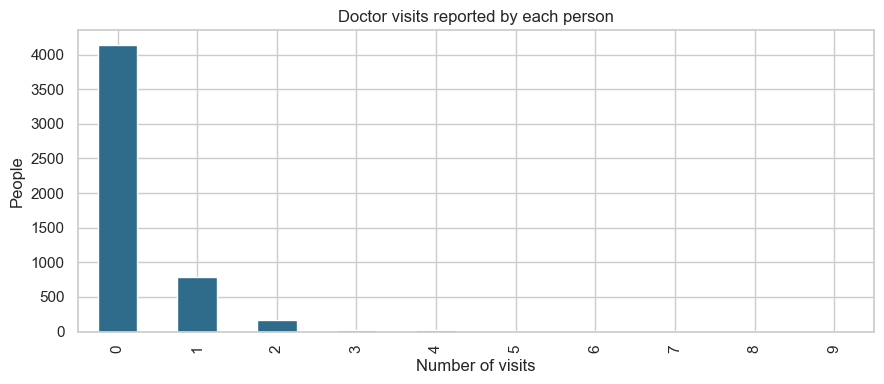

In [27]:
counts = df.visits.value_counts().sort_index()
print(pd.DataFrame({"people":counts,"share (%)":(counts/len(df)*100).round(1)}))
print(f"Mean visits: {df.visits.mean():.3f}; median: {df.visits.median():.0f}")
print(f"No visit: {(df.visits==0).sum():,} ({(df.visits==0).mean():.1%})")
print(f"One or more: {(df.visits>0).sum():,} ({(df.visits>0).mean():.1%})")

# Visualization
ax=counts.plot.bar(figsize=(9,4),color="#2F6B8A")
ax.set(title="Doctor visits reported by each person",xlabel="Number of visits",ylabel="People")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\visitbyeach.png')
plt.tight_layout()
plt.show()


### Distribution takeaway
Most people reported no doctor visits. Since almost four in five records are zero, averages alone hide the difference between people with no visits and the smaller group with one or more.

## 4. Exploratory comparisons
Quartiles below are relative ranks within this file. They must not be interpreted as real age or currency bands.

Average visits by age_quartile


,size,mean,median
age_quartile,,,
Q1 lowest,1965,0.205598,0.0
Q2,824,0.252427,0.0
Q3,1264,0.346519,0.0
Q4 highest,1137,0.453826,0.0


Average visits by income_quartile


,size,mean,median
income_quartile,,,
Q1 lowest,1638,0.398046,0.0
Q2,1329,0.305493,0.0
Q3,1485,0.230303,0.0
Q4 highest,738,0.224932,0.0


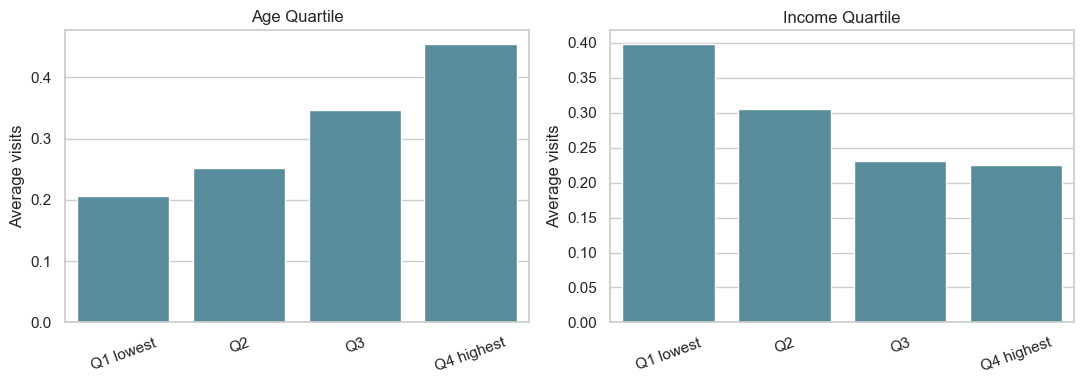

Visits by illness


,people,average,median
illness,,,
0,1554,0.078507,0.0
1,1638,0.295482,0.0
2,946,0.403805,0.0
3,542,0.420664,0.0
4,274,0.576642,0.0
5,236,0.813559,0.0


Visits by reduced


,people,average,median
reduced,,,
0,4454,0.183880,0.0
1,177,0.355932,0.0
2,108,0.574074,0.0
3,74,1.094595,1.0
4,45,0.800000,1.0
5,40,1.275000,1.0
6,17,1.176471,1.0
7,38,1.184211,1.0
8,17,1.176471,1.0


Visits by health


,people,average,median
health,,,
0,3026,0.199273,0.0
1,823,0.335358,0.0
2,446,0.381166,0.0
3,273,0.417582,0.0
4,187,0.534759,0.0
5,132,0.530303,0.0
6,104,0.625000,0.0
7,61,0.918033,0.0
8,42,0.476190,0.0


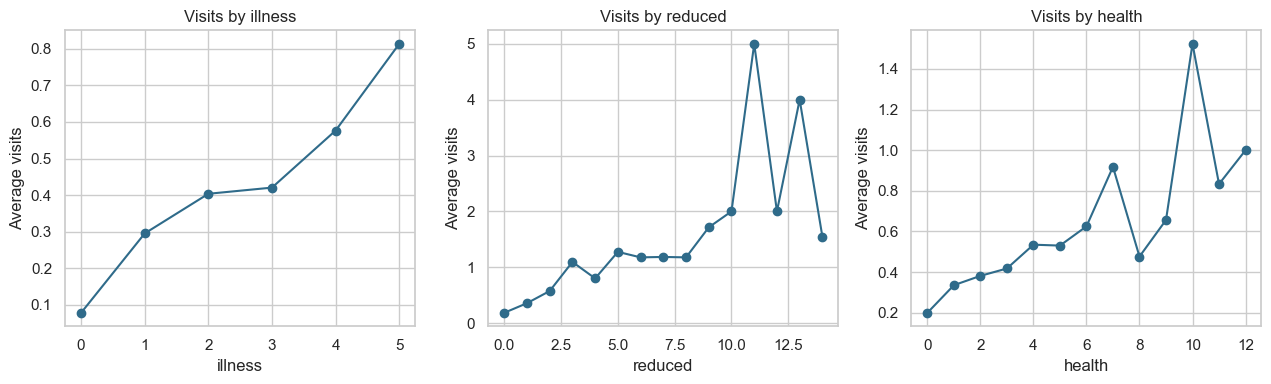

In [28]:
df["age_quartile"]=pd.qcut(df.age,4,labels=["Q1 lowest","Q2","Q3","Q4 highest"],duplicates="drop")
df["income_quartile"]=pd.qcut(df.income,4,labels=["Q1 lowest","Q2","Q3","Q4 highest"],duplicates="drop")

for c in ["age_quartile","income_quartile"]:
    print("Average visits by",c); display(df.groupby(c,observed=True).visits.agg(["size","mean","median"]))

fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,c in zip(axes,["age_quartile","income_quartile"]):
    sns.barplot(data=df,x=c,y="visits",errorbar=None,ax=ax,color="#4C91A8")
    ax.set(xlabel="",ylabel="Average visits",title=c.replace("_"," ").title()); ax.tick_params(axis="x",rotation=20)
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\quartilebyage_income.png')
plt.tight_layout()
plt.show()

for c in ["illness","reduced","health"]:
    print("Visits by",c); display(df.groupby(c,observed=True).visits.agg(people="size",average="mean",median="median"))

fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,c in zip(axes,["illness","reduced","health"]):
    df.groupby(c,observed=True).visits.mean().plot(ax=ax,marker="o",color="#2F6B8A")
    ax.set(xlabel=c,ylabel="Average visits",title=f"Visits by {c}")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\visitbyillness_reduced_health.png')
plt.tight_layout()
plt.show()

        field   group  people  average visits  any visit (%)
0      gender  female    2702            0.36          24.43
1      gender    male    2488            0.24          15.64
2     private      no    2892            0.31          20.37
3     private     yes    2298            0.29          20.02
4    freepoor      no    4968            0.31          20.71
5    freepoor     yes     222            0.16           9.01
6   freerepat      no    4099            0.26          17.17
7   freerepat     yes    1091            0.47          31.62
8    nchronic      no    3098            0.27          17.88
9    nchronic     yes    2092            0.35          23.66
10   lchronic      no    4585            0.26          18.26
11   lchronic     yes     605            0.60          35.04


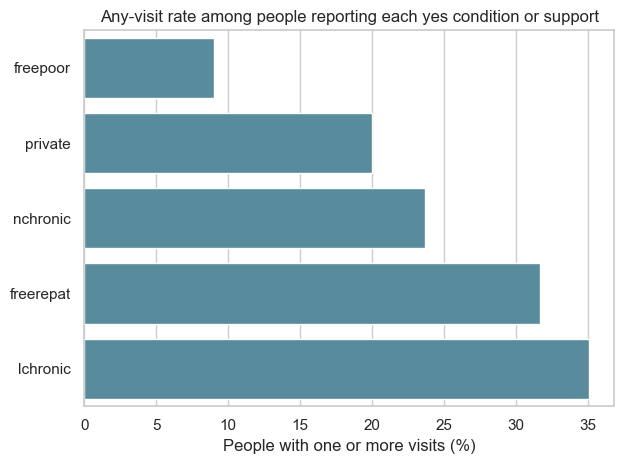

In [29]:
group_rows=[]
for c in ["gender","private","freepoor","freerepat","nchronic","lchronic"]:
    for level,g in df.groupby(c,observed=True):
        group_rows.append({"field":c,"group":str(level),"people":len(g),
                           "average visits":g.visits.mean(),"any visit (%)":(g.visits>0).mean()*100})
groups=pd.DataFrame(group_rows)
print(groups.round(2))
plot=groups[groups.group=="yes"].sort_values("any visit (%)")

# Visualization
ax=sns.barplot(data=plot,x="any visit (%)",y="field",color="#4C91A8")
ax.set(title="Any-visit rate among people reporting each yes condition or support",xlabel="People with one or more visits (%)",ylabel="")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\visitrate.png')
plt.tight_layout()
plt.show()

## 5. Association screening
Spearman correlation suits skewed counts and coded or ordinal fields. Holm adjustment reduces false positives across the five related comparisons. A small p-value does not mean a large effect.

In [30]:
rows=[]
for c in ["age","income","illness","reduced","health"]:
    rho,p=stats.spearmanr(df[c],df.visits)
    rows.append({"field":c,"Spearman correlation":rho,"raw p-value":p})
screen=pd.DataFrame(rows)
screen["Holm adjusted p-value"]=multipletests(screen["raw p-value"],method="holm")[1]
display(screen.sort_values("Spearman correlation",key=lambda s:s.abs(),ascending=False).round(4))

,field,Spearman correlation,raw p-value,Holm adjusted p-value
3,reduced,0.3356,0.0,0.0
2,illness,0.2627,0.0,0.0
4,health,0.1775,0.0,0.0
0,age,0.1476,0.0,0.0
1,income,-0.0928,0.0,0.0


Activity reduction and illness have the clearest positive rank relationships with visits. Age and the numeric health code have smaller positive relationships; income has a small negative relationship. These are unadjusted patterns. The direction of the health code is not defined, so its sign cannot be translated as better or worse health.

## 6. Validation with an adjusted model
A logistic model checks which fields are associated with having any visit while accounting for the other listed fields. Odds ratios complement, but do not replace, the count analysis. Numeric fields are treated as having a steady per-unit relationship in this screening model.

In [31]:
df["any_visit"]=(df.visits>0).astype(int)
formula=("any_visit ~ age + income + illness + reduced + health + C(gender) + C(private) + "
         "C(freepoor) + C(freerepat) + C(nchronic) + C(lchronic)")
model=smf.logit(formula,data=df).fit(disp=False)
ci=model.conf_int()
odds=pd.DataFrame({"odds ratio":np.exp(model.params),"95% CI low":np.exp(ci[0]),
                   "95% CI high":np.exp(ci[1]),"p-value":model.pvalues}).drop(index="Intercept").sort_values("p-value")
print(odds.round(3))
print(f"Overall likelihood-ratio p-value: {model.llr_pvalue:.3g}")
print(f"Pseudo R-squared: {model.prsquared:.3f}; this is not prediction accuracy.")

                     odds ratio  95% CI low  95% CI high  p-value
reduced                   1.171       1.144        1.199    0.000
illness                   1.305       1.233        1.381    0.000
health                    1.063       1.028        1.100    0.000
C(gender)[T.male]         0.771       0.656        0.906    0.002
C(freerepat)[T.yes]       1.522       1.158        2.001    0.003
C(freepoor)[T.yes]        0.502       0.301        0.838    0.008
C(private)[T.yes]         1.297       1.065        1.579    0.010
age                       1.611       0.992        2.616    0.054
C(lchronic)[T.yes]        1.265       0.991        1.615    0.059
C(nchronic)[T.yes]        1.100       0.920        1.315    0.298
income                    0.946       0.746        1.199    0.646
Overall likelihood-ratio p-value: 1.36e-135
Pseudo R-squared: 0.127; this is not prediction accuracy.


### Validation interpretation
Illness count and days of reduced activity remain clearly associated with having any visit after adjustment. Their odds ratios are about 1.31 per additional illness and 1.17 per additional reduced-activity day. These depend on the model's steady per-unit assumption and are not causal effects. The raw gender difference also remains. Private coverage has almost no raw mean difference, but its adjusted association differs after controlling for other fields, showing why single-variable comparisons can mislead. The long-term chronic-condition gap is substantial in raw data but weaker after adjustment; related health fields overlap.

# 7. Findings 

In [32]:
# Color 
TEAL = "#61AEB8"
NAVY = "#2F526D"
ORANGE = "#E5A44B"
MUTED = "#66727D"

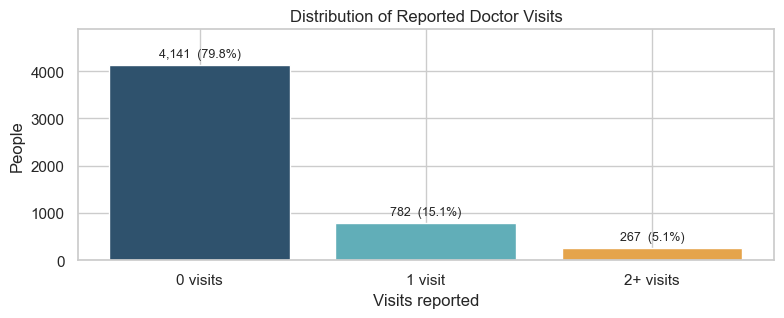

In [33]:
# Finding 1: the visit distribution is strongly concentrated at zero.
bucket_counts = pd.Series({
    "0 visits": int((df.visits == 0).sum()),
    "1 visit": int((df.visits == 1).sum()),
    "2+ visits": int((df.visits >= 2).sum())
})

fig, ax = plt.subplots(figsize=(8.0,3.35))
bars = ax.bar(bucket_counts.index, bucket_counts.values, color=[NAVY,TEAL,ORANGE])
ax.set_title("Distribution of Reported Doctor Visits")
ax.set_xlabel("Visits reported"); ax.set_ylabel("People")
ax.set_ylim(0, max(bucket_counts.values)*1.18)
for bar, count in zip(bars, bucket_counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(bucket_counts.values)*.025,
            f"{count:,}  ({count/len(df):.1%})", ha="center", va="bottom", fontsize=9)
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\distributionofvisits.png')
plt.tight_layout()
plt.show()


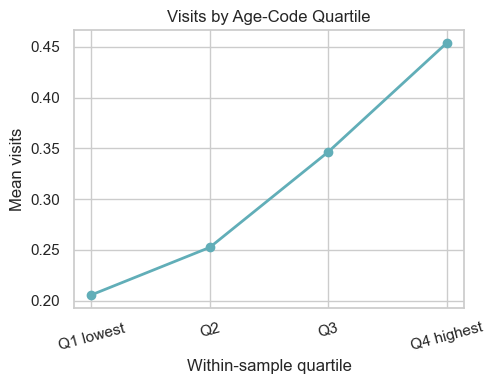

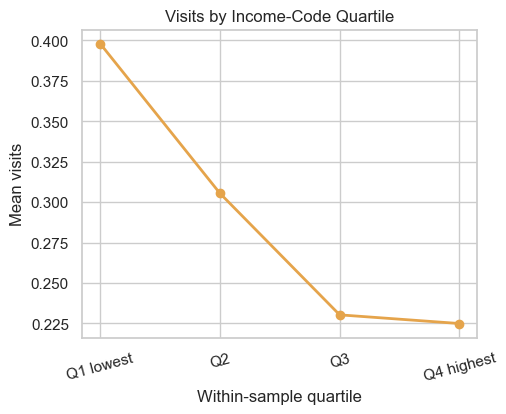

<Figure size 640x480 with 0 Axes>

In [34]:
# Finding 2: descriptive quartiles on code-like age and income scales.
fig, ax = plt.subplots(figsize=(5.1,4.0))
age_means = df.groupby("age_quartile", observed=True).visits.mean()
ax.plot(range(len(age_means)), age_means.values, marker="o", color=TEAL, linewidth=2)
ax.set_xticks(range(len(age_means)), [str(x) for x in age_means.index], rotation=15)
ax.set(title="Visits by Age-Code Quartile", xlabel="Within-sample quartile", ylabel="Mean visits")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\visitsbyagecode.png')
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(5.1,4.0))
income_means = df.groupby("income_quartile", observed=True).visits.mean()
ax.plot(range(len(income_means)), income_means.values, marker="o", color=ORANGE, linewidth=2)
ax.set_xticks(range(len(income_means)), [str(x) for x in income_means.index], rotation=15)
ax.set(title="Visits by Income-Code Quartile", xlabel="Within-sample quartile", ylabel="Mean visits")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\visitsbyincomecode.png')
plt.show()
plt.tight_layout()

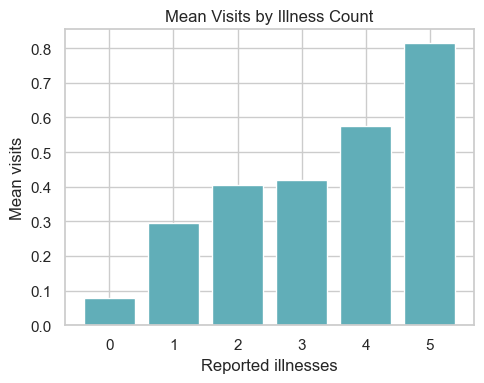

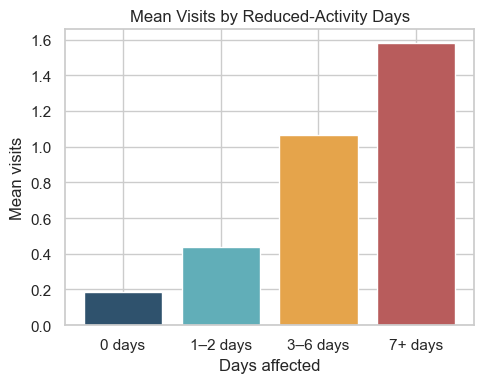

In [35]:
# Finding 3: illness count and activity disruption show the clearest raw gradients.
fig, ax = plt.subplots(figsize=(5.0,4.0))
illness_means = df.groupby("illness", observed=True).visits.mean()
ax.bar(illness_means.index.astype(str), illness_means.values, color=TEAL)
ax.set(title="Mean Visits by Illness Count", xlabel="Reported illnesses", ylabel="Mean visits")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\meanvisitsbyillness.png')
plt.tight_layout()
plt.show()


df["reduced_band"] = pd.cut(df["reduced"], [-1,0,2,6,14],
                            labels=["0 days","1–2 days","3–6 days","7+ days"])
fig, ax = plt.subplots(figsize=(5.0,4.0))
reduced_means = df.groupby("reduced_band", observed=True).visits.mean()
ax.bar([str(x) for x in reduced_means.index], reduced_means.values,
       color=[NAVY,TEAL,ORANGE,"#B85C5C"])
ax.set(title="Mean Visits by Reduced-Activity Days", xlabel="Days affected", ylabel="Mean visits")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\meanvisitsbyreduced.png')
plt.tight_layout()
plt.show()


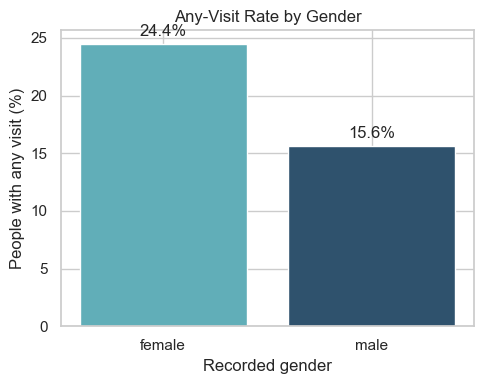

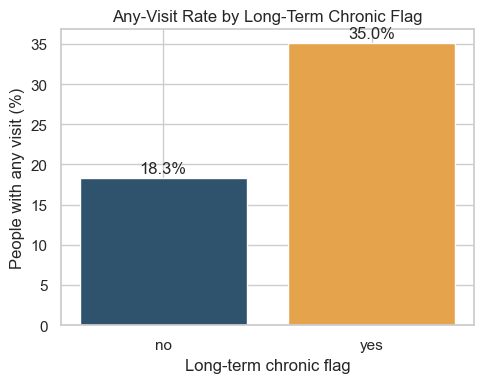

In [36]:
# Finding 4: unadjusted rates are useful for describing the sample, not for assigning cause.
fig, ax = plt.subplots(figsize=(5.0,4.0))
gender_rates = (df.groupby("gender", observed=True).any_visit.mean()*100)
ax.bar(gender_rates.index.astype(str), gender_rates.values, color=[TEAL,NAVY])
ax.set(title="Any-Visit Rate by Gender", xlabel="Recorded gender", ylabel="People with any visit (%)")
for i,v in enumerate(gender_rates.values): ax.text(i,v+0.7,f"{v:.1f}%",ha="center")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\visitratebygender.png')
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(5.0,4.0))
chronic_rates = (df.groupby("lchronic", observed=True).any_visit.mean()*100)
ax.bar(chronic_rates.index.astype(str), chronic_rates.values, color=[NAVY,ORANGE])
ax.set(title="Any-Visit Rate by Long-Term Chronic Flag", xlabel="Long-term chronic flag", ylabel="People with any visit (%)")
for i,v in enumerate(chronic_rates.values): ax.text(i,v+0.7,f"{v:.1f}%",ha="center")
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\visitsratebychronic.png')
plt.tight_layout()
plt.show()


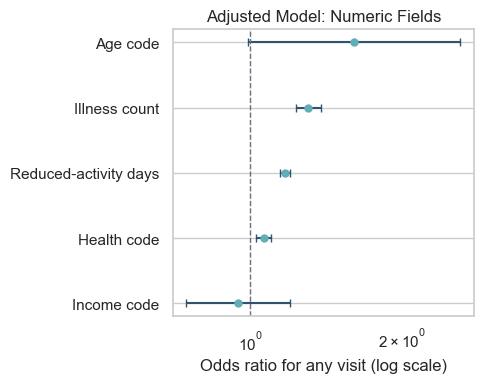

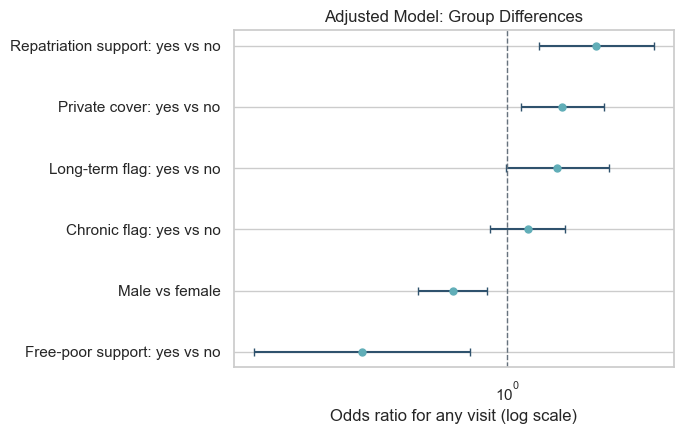

In [39]:
# Finding 5: Adjusted odds ratios for numeric fields

terms = ["age", "income", "illness", "reduced", "health"]

labels = {
    "age": "Age code",
    "income": "Income code",
    "illness": "Illness count",
    "reduced": "Reduced-activity days",
    "health": "Health code"
}

table = odds.loc[terms].copy().sort_values("odds ratio")

fig, ax = plt.subplots(figsize=(5.0, 4.0))

y = np.arange(len(table))
x = table["odds ratio"].to_numpy()

low = x - table["95% CI low"].to_numpy()
high = table["95% CI high"].to_numpy() - x

ax.errorbar(
    x, y,
    xerr=[low, high],
    fmt="o",
    color=TEAL,
    ecolor=NAVY,
    capsize=3,
    markersize=5
)

ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)

ax.set_yticks(y, [labels[t] for t in table.index])

ax.set_xscale("log")

ax.set(
    title="Adjusted Model: Numeric Fields",
    xlabel="Odds ratio for any visit (log scale)",
    ylabel=""
)

ax.grid(axis="x", alpha=0.25)

plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\modelnumeric.png')
plt.tight_layout()
plt.show()

# Finding 5: Adjusted odds ratios for categorical fields

terms = [
    "C(gender)[T.male]",
    "C(private)[T.yes]",
    "C(freepoor)[T.yes]",
    "C(freerepat)[T.yes]",
    "C(nchronic)[T.yes]",
    "C(lchronic)[T.yes]"
]

labels = {
    "C(gender)[T.male]": "Male vs female",
    "C(private)[T.yes]": "Private cover: yes vs no",
    "C(freepoor)[T.yes]": "Free-poor support: yes vs no",
    "C(freerepat)[T.yes]": "Repatriation support: yes vs no",
    "C(nchronic)[T.yes]": "Chronic flag: yes vs no",
    "C(lchronic)[T.yes]": "Long-term flag: yes vs no"
}

table = odds.loc[terms].copy().sort_values("odds ratio")

fig, ax = plt.subplots(figsize=(7.0, 4.5))

y = np.arange(len(table))
x = table["odds ratio"].to_numpy()

low = x - table["95% CI low"].to_numpy()
high = table["95% CI high"].to_numpy() - x

ax.errorbar(
    x, y,
    xerr=[low, high],
    fmt="o",
    color=TEAL,
    ecolor=NAVY,
    capsize=3,
    markersize=5
)

ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)

ax.set_yticks(y, [labels[t] for t in table.index])

ax.set_xscale("log")
ax.xaxis.set_minor_locator(plt.NullLocator())

ax.set(
    title="Adjusted Model: Group Differences",
    xlabel="Odds ratio for any visit (log scale)",
    ylabel=""
)

ax.grid(axis="x", alpha=0.25)

plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\modelcategorical.png')
plt.tight_layout()
plt.show()

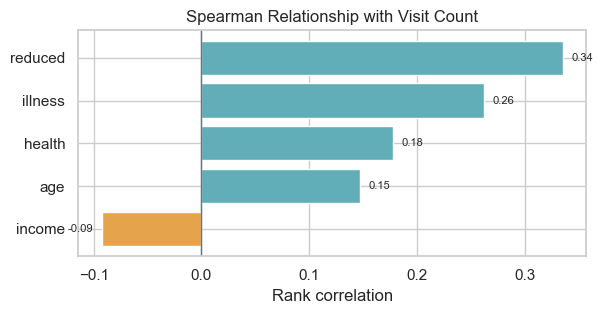

In [38]:
# Finding 6: rank correlations give a second, non-parametric check of numeric patterns.
fig, ax = plt.subplots(figsize=(6.2,3.3))
corr = screen.sort_values("Spearman correlation")
colors = [ORANGE if v < 0 else TEAL for v in corr["Spearman correlation"]]
ax.barh(corr["field"], corr["Spearman correlation"], color=colors)
ax.axvline(0,color=MUTED,linewidth=1)
ax.set(title="Spearman Relationship with Visit Count", xlabel="Rank correlation", ylabel="")
for y, value in enumerate(corr["Spearman correlation"]):
    ax.text(value + (0.008 if value >= 0 else -0.008), y,
            f"{value:.2f}", va="center", ha="left" if value >= 0 else "right", fontsize=8)
plt.savefig(r'C:\VOIS Internship\Health Care Part 2\output\spearman.png')
plt.tight_layout()
plt.show()

## 8. Actionable insights and limits

1. **Plan around reported health needs.** Illness and reduced activity have the strongest, most consistent links with visits. Examine whether people reporting several illnesses or disrupted daily activity have appropriate access and continuity of care.
2. **Review access differences.** Visit rates differ by gender and support categories. Investigate whether need, access, or reporting differs; do not use group membership alone to ration care.
3. **Interpret coverage comparisons with adjustment.** Similar raw averages for private coverage coexist with a different adjusted association. Study need and confounding before drawing conclusions about coverage.
4. **Improve the data brief.** Document the survey period, sampling method, age and income scales, health-code direction, and coverage definitions.
5. **Validate before operational use.** Confirm these patterns in newer, representative data and model visit counts before using findings for staffing decisions.

This observational file does not establish cause, care quality, unmet need, or a visit rate per unit of time. The any-visit model is a screening analysis, not a clinical risk score.